# 01 Data check

**Notebook 1 of 6, xBD building damage assessment**

Inspection and cleaning of the xBD data before any training: class encoding of
the targets, generation of the missing Tier3 targets, nodata filtering, class
distribution per event, and the live cropping dataset used by all later
notebooks.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import json
from collections import Counter, defaultdict

import numpy as np
from PIL import Image
import matplotlib.pyplot as pl
from shapely import wkt
from skimage.draw import polygon2mask

import config
from common import data, crops

pl.rcParams["figure.dpi"] = 120

paths = data.resolve_splits(config.DATA_ROOT)
file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
print("data root:", config.DATA_ROOT)
for split in config.SPLIT_FOLDERS:
    if split not in paths:
        print(f"{split}: not found, skipped")
for split, files in file_lists.items():
    print(f"{split}: {len(files)} pre-disaster images")


data root: /DATA/schrepel/xbd_new/data
train: 2746 pre-disaster images
test: 917 pre-disaster images
hold: 933 pre-disaster images
tier3: 6288 pre-disaster images


## 1. Class encoding of the targets

Train ships ready made target PNGs. Tier3 does not, so we first check which
pixel value each label subtype gets in the official targets and then reuse that
encoding.

In [2]:
def get_all_target_values(split):
    target_dir = paths[split]["targets"]
    found_values = Counter()

    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(os.path.join(target_dir, f"{stem}_post_disaster_target.png")))
        values, counts = np.unique(target, return_counts=True)
        for v, c in zip(values, counts):
            found_values[int(v)] += int(c)

    return found_values


for value, count in sorted(get_all_target_values("train").items()):
    print(f"value {value}: {count:,} pixels")

value 0: 2,706,354,173 pixels
value 1: 127,778,766 pixels
value 2: 15,857,696 pixels
value 3: 20,033,859 pixels
value 4: 9,365,202 pixels


For each subtype we look up the pixel value at the location of its labelled
polygons.

In [3]:
def check_subtype_to_value(split, subtype, max_images=100):
    label_dir, target_dir = paths[split]["labels"], paths[split]["targets"]
    pixel_values = Counter()
    images_checked = 0

    for pre_image in file_lists[split]:
        if images_checked >= max_images:
            break

        stem = pre_image.replace("_pre_disaster.png", "")
        with open(os.path.join(label_dir, f"{stem}_post_disaster.json")) as f:
            labels = json.load(f)

        matching = [f for f in labels["features"]["xy"]
                    if f["properties"].get("subtype") == subtype]
        if not matching:
            continue

        target = np.array(Image.open(os.path.join(target_dir, f"{stem}_post_disaster_target.png")))
        for feature in matching:
            coords = np.array(wkt.loads(feature["wkt"]).exterior.coords)
            mask = polygon2mask(target.shape, coords[:, ::-1])
            values, counts = np.unique(target[mask], return_counts=True)
            for v, c in zip(values, counts):
                pixel_values[int(v)] += int(c)

        images_checked += 1

    return pixel_values


subtypes = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]

for subtype in subtypes:
    result = check_subtype_to_value("train", subtype)
    if not result:
        print(f"{subtype:15s}: not found")
        continue
    total = sum(result.values())
    value, count = result.most_common(1)[0]
    print(f"{subtype:15s}: value {value} ({100 * count / total:.1f}% of its pixels)")

no-damage      : value 1 (100.0% of its pixels)


minor-damage   : value 2 (100.0% of its pixels)


major-damage   : value 3 (100.0% of its pixels)


destroyed      : value 4 (100.0% of its pixels)


un-classified  : value 0 (100.0% of its pixels)


So `no-damage` is 1, `minor-damage` 2, `major-damage` 3, `destroyed` 4, and
`un-classified` counts as background 0.

## 2. Missing targets

Train, test and the holdout set ship ready made target PNGs, tier3 only comes
with the raw label polygons. Those targets are rasterized with the encoding
above. The cell skips files that already exist and can be rerun safely.

In [4]:
# Train, test and the holdout set ship ready made target PNGs, tier3 does not.
# Missing targets are rasterized from the label polygons with the encoding above.
for split in paths:
    os.makedirs(paths[split]["targets"], exist_ok=True)
    n_created = 0

    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        for suffix in ["pre_disaster", "post_disaster"]:
            target_path = os.path.join(paths[split]["targets"], f"{stem}_{suffix}_target.png")
            if os.path.exists(target_path):
                continue

            target = data.json_to_target(os.path.join(paths[split]["labels"], f"{stem}_{suffix}.json"))
            Image.fromarray(target).save(target_path)
            n_created += 1

    print(f"{split}: {n_created} targets created")

train: 0 targets created
test: 0 targets created
hold: 0 targets created
tier3: 0 targets created


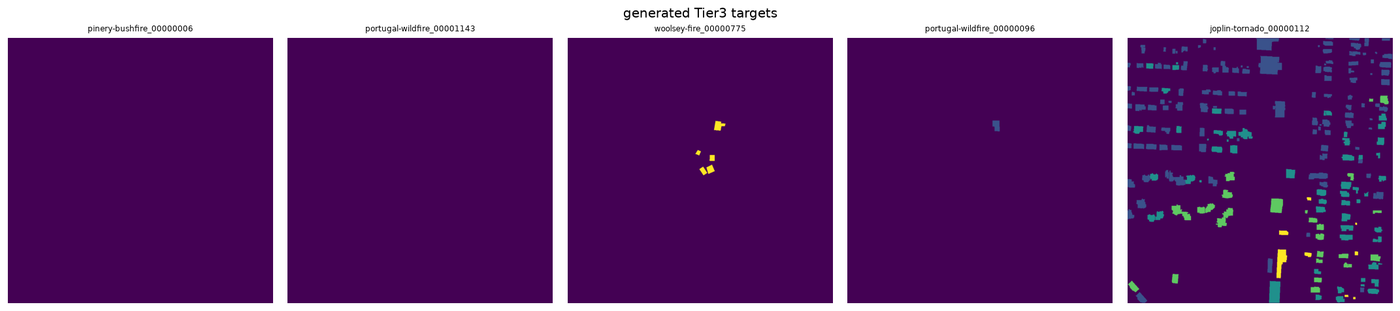

In [5]:
sample_stems = np.random.choice(file_lists["tier3"], 5, replace=False)

fig, ax = pl.subplots(1, 5, figsize=(18, 4))
for a, pre_image in zip(ax, sample_stems):
    stem = pre_image.replace("_pre_disaster.png", "")
    target = np.array(Image.open(
        os.path.join(paths["tier3"]["targets"], f"{stem}_post_disaster_target.png")))
    a.imshow(target, cmap="viridis", vmin=0, vmax=4)
    a.set_title(stem, fontsize=7)
    a.axis("off")

fig.suptitle("generated Tier3 targets")
pl.tight_layout()
pl.show()

## 3. Nodata

Many tiles have black borders without image information (channel sum 0). Images
that consist mostly of such pixels are useless for training.

In [6]:
all_fractions = {
    split: np.array([data.nodata_fraction(os.path.join(paths[split]["images"], f))
                     for f in file_lists[split]])
    for split in paths
}

for split, fractions in all_fractions.items():
    print(f"\n{split}:")
    for threshold in [0.1, 0.3, 0.5, 0.7]:
        n = (fractions > threshold).sum()
        print(f"  > {int(threshold * 100):2d}% nodata: {n:4d}/{len(fractions)} ({100 * n / len(fractions):4.1f}%)")


train:
  > 10% nodata:  286/2746 (10.4%)
  > 30% nodata:  142/2746 ( 5.2%)
  > 50% nodata:   36/2746 ( 1.3%)
  > 70% nodata:    0/2746 ( 0.0%)

test:
  > 10% nodata:   98/917 (10.7%)
  > 30% nodata:   55/917 ( 6.0%)
  > 50% nodata:    8/917 ( 0.9%)
  > 70% nodata:    0/917 ( 0.0%)

hold:
  > 10% nodata:  109/933 (11.7%)
  > 30% nodata:   65/933 ( 7.0%)
  > 50% nodata:   31/933 ( 3.3%)
  > 70% nodata:    9/933 ( 1.0%)

tier3:
  > 10% nodata:  571/6288 ( 9.1%)
  > 30% nodata:  301/6288 ( 4.8%)
  > 50% nodata:   91/6288 ( 1.4%)
  > 70% nodata:    0/6288 ( 0.0%)


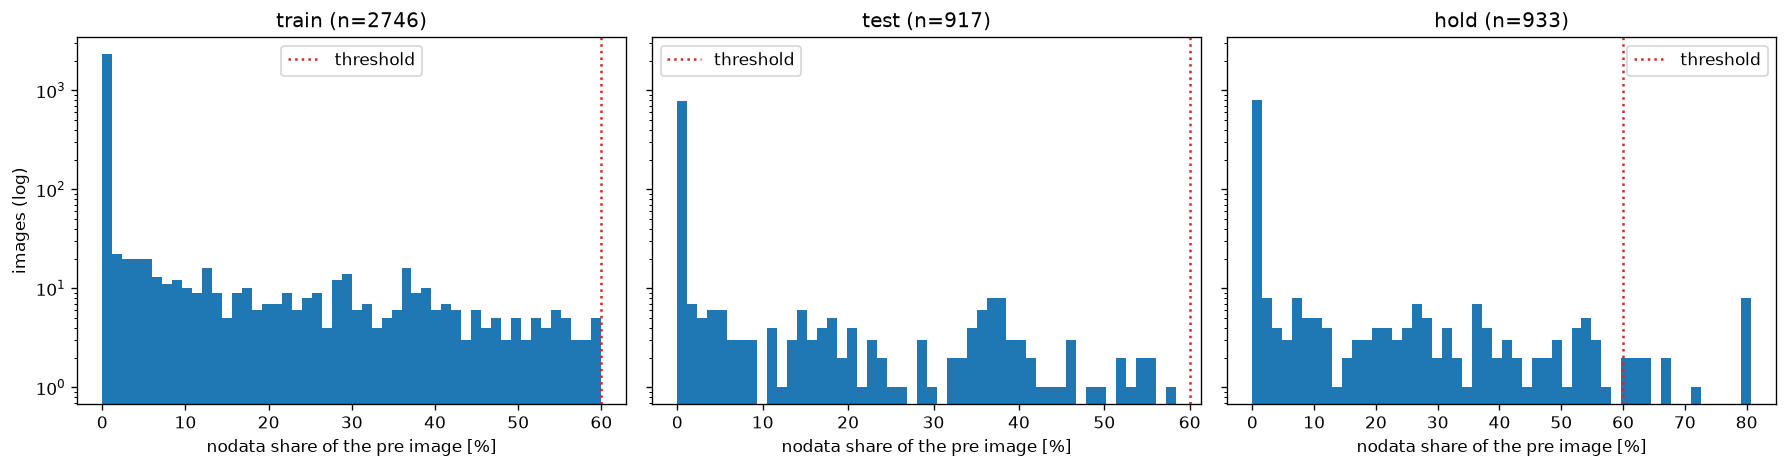

In [7]:
fig, ax = pl.subplots(1, 3, figsize=(15, 4), sharey=True)

for a, (split, fractions) in zip(ax, all_fractions.items()):
    a.hist(100 * fractions, bins=50, color="C0")
    a.axvline(60, color="C3", linestyle=":", label="threshold")
    a.set_yscale("log")
    a.set_xlabel("nodata share of the pre image [%]")
    a.set_title(f"{split} (n={len(fractions)})")
    a.legend()

ax[0].set_ylabel("images (log)")
pl.tight_layout()
pl.show()

Set `DELETE_NODATA_FILES = True` to actually delete from disk. The holdout split
is protected: it is only used for the final evaluation and stays untouched.

In [8]:
DELETE_NODATA_FILES = False

stems_to_delete = {split: [] for split in paths}

for split in paths:
    if split in config.PROTECTED_SPLITS:
        continue
    image_dir = paths[split]["images"]
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        post_path = os.path.join(image_dir, f"{stem}_post_disaster.png")

        pre_frac = data.nodata_fraction(os.path.join(image_dir, pre_image))
        post_frac = data.nodata_fraction(post_path) if os.path.exists(post_path) else 0.0

        if max(pre_frac, post_frac) > config.NODATA_THRESHOLD:
            stems_to_delete[split].append(stem)

for split, stems in stems_to_delete.items():
    print(f"{split}: {len(stems)} images above {int(config.NODATA_THRESHOLD * 100)}% nodata")

train: 0 images above 60% nodata
test: 0 images above 60% nodata
hold: 0 images above 60% nodata
tier3: 0 images above 60% nodata


In [9]:
if DELETE_NODATA_FILES:
    n_deleted = 0
    for split, stems in stems_to_delete.items():
        for stem in stems:
            candidates = [
                os.path.join(paths[split]["images"],  f"{stem}_pre_disaster.png"),
                os.path.join(paths[split]["images"],  f"{stem}_post_disaster.png"),
                os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png"),
                os.path.join(paths[split]["targets"], f"{stem}_post_disaster_target.png"),
                os.path.join(paths[split]["labels"],  f"{stem}_pre_disaster.json"),
                os.path.join(paths[split]["labels"],  f"{stem}_post_disaster.json"),
            ]
            for path in candidates:
                if os.path.exists(path):
                    os.remove(path)
                    n_deleted += 1

    print(f"{n_deleted} files deleted")
    file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
    for split, files in file_lists.items():
        print(f"{split}: {len(files)} images left")
else:
    print("test run, nothing deleted")

test run, nothing deleted


## 4. Consistency

Every pre image needs a matching post image, both targets and both label files,
and no post file may be left without its pre image.

In [10]:
def find_incomplete_stems(split):
    incomplete = []
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        expected = [
            os.path.join(paths[split]["images"],  f"{stem}_post_disaster.png"),
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png"),
            os.path.join(paths[split]["targets"], f"{stem}_post_disaster_target.png"),
            os.path.join(paths[split]["labels"],  f"{stem}_pre_disaster.json"),
            os.path.join(paths[split]["labels"],  f"{stem}_post_disaster.json"),
        ]
        if any(not os.path.exists(p) for p in expected):
            incomplete.append(stem)
    return incomplete


def find_orphaned_post_files(split):
    pre_stems = {f.replace("_pre_disaster.png", "") for f in file_lists[split]}
    orphaned = []

    for folder, pattern in [(paths[split]["images"],  "_post_disaster.png"),
                            (paths[split]["targets"], "_post_disaster_target.png"),
                            (paths[split]["labels"],  "_post_disaster.json")]:
        for filename in os.listdir(folder):
            if filename.endswith(pattern) and filename.replace(pattern, "") not in pre_stems:
                orphaned.append(os.path.join(folder, filename))
    return orphaned


for split in paths:
    print(f"{split:6s}: {len(find_incomplete_stems(split))} incomplete pairs, "
          f"{len(find_orphaned_post_files(split))} orphaned post files")

train : 0 incomplete pairs, 0 orphaned post files
test  : 0 incomplete pairs, 0 orphaned post files
hold  : 0 incomplete pairs, 0 orphaned post files


tier3 : 0 incomplete pairs, 0 orphaned post files


## 5. Events per split

In [11]:
event_counts = {split: Counter(f.split("_")[0] for f in file_lists[split]) for split in paths}

for split, counts in event_counts.items():
    print(f"\n{split}: {len(counts)} events")
    for disaster, n in sorted(counts.items()):
        print(f"  {disaster:22s}: {n:5d}")


train: 10 events
  guatemala-volcano     :    18
  hurricane-florence    :   316
  hurricane-harvey      :   312
  hurricane-matthew     :   238
  hurricane-michael     :   340
  mexico-earthquake     :   121
  midwest-flooding      :   273
  palu-tsunami          :   106
  santa-rosa-wildfire   :   215
  socal-fire            :   807

test: 10 events
  guatemala-volcano     :     5
  hurricane-florence    :   106
  hurricane-harvey      :   107
  hurricane-matthew     :    73
  hurricane-michael     :    97
  mexico-earthquake     :    38
  midwest-flooding      :    79
  palu-tsunami          :    41
  santa-rosa-wildfire   :    69
  socal-fire            :   302

hold: 10 events
  guatemala-volcano     :     5
  hurricane-florence    :   119
  hurricane-harvey      :    95
  hurricane-matthew     :    94
  hurricane-michael     :   109
  mexico-earthquake     :    34
  midwest-flooding      :    86
  palu-tsunami          :    41
  santa-rosa-wildfire   :    77
  socal-fire        

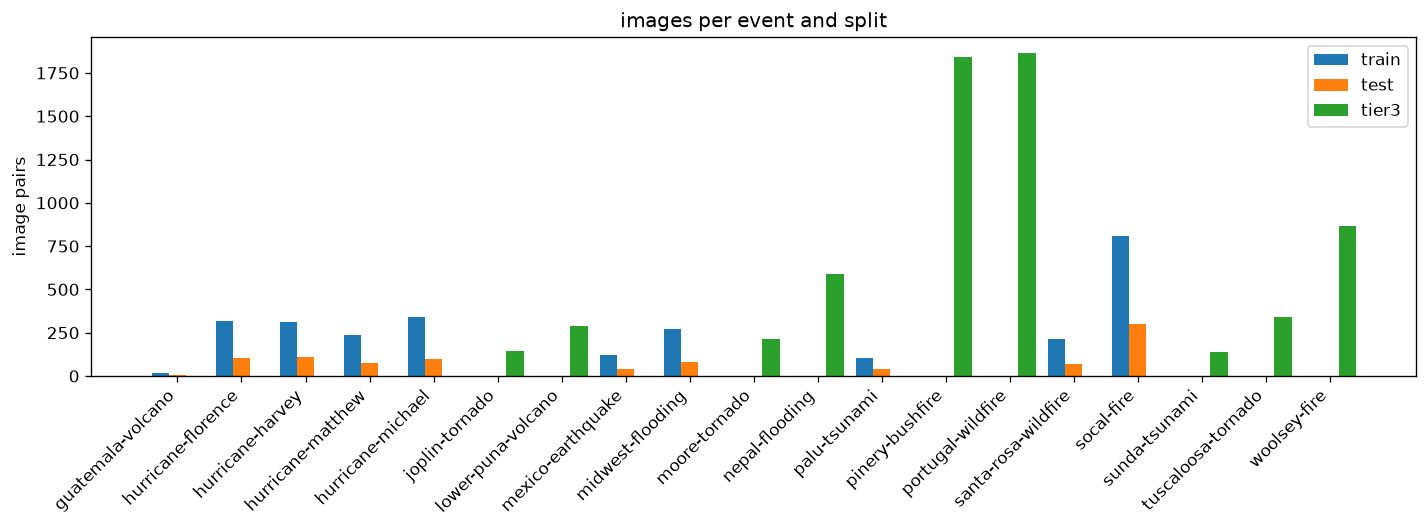

In [12]:
all_events = sorted(set().union(*(c.keys() for c in event_counts.values())))
x = np.arange(len(all_events))
width = 0.27

pl.figure(figsize=(12, 4.5))
for offset, (split, color) in zip([-width, 0, width],
                                  [("train", "C0"), ("test", "C1"), ("tier3", "C2")]):
    pl.bar(x + offset, [event_counts[split].get(e, 0) for e in all_events],
           width, label=split, color=color)

pl.xticks(x, all_events, rotation=45, ha="right")
pl.ylabel("image pairs")
pl.title("images per event and split")
pl.legend()
pl.tight_layout()
pl.show()

In [13]:
# Which events appear in which split, and does a split bring events of its own?
events_by_split = {split: set(event_counts[split]) for split in event_counts}
all_event_names = sorted(set().union(*events_by_split.values()))

print(f"{'event':24s}" + "".join(f"{split:>8s}" for split in events_by_split))
for event in all_event_names:
    print(f"{event:24s}" + "".join(f"{event_counts[split].get(event, 0):>8d}" for split in events_by_split))

print()
for split, events in events_by_split.items():
    others = set().union(*(e for s, e in events_by_split.items() if s != split))
    unique = sorted(events - others)
    print(f"{split:6s}: {len(events)} events, only in this split: {unique if unique else 'none'}")

event                      train    test    hold   tier3
guatemala-volcano             18       5       5       0
hurricane-florence           316     106     119       0
hurricane-harvey             312     107      95       0
hurricane-matthew            238      73      94       0
hurricane-michael            340      97     109       0
joplin-tornado                 0       0       0     142
lower-puna-volcano             0       0       0     291
mexico-earthquake            121      38      34       0
midwest-flooding             273      79      86       0
moore-tornado                  0       0       0     216
nepal-flooding                 0       0       0     591
palu-tsunami                 106      41      41       0
pinery-bushfire                0       0       0    1839
portugal-wildfire              0       0       0    1863
santa-rosa-wildfire          215      69      77       0
socal-fire                   807     302     273       0
sunda-tsunami                  

## 6. Class distribution per event

How the building pixels of the post target spread across the four damage
classes. The distribution differs strongly between events.

In [14]:
CLASS_NAMES = {1: "no-damage", 2: "minor", 3: "major", 4: "destroyed"}


def damage_percentages(split):
    stats = defaultdict(lambda: {1: 0, 2: 0, 3: 0, 4: 0})

    for pre_image in file_lists[split]:
        disaster = pre_image.split("_")[0]
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_post_disaster_target.png")))

        values, counts = np.unique(target, return_counts=True)
        for v, c in zip(values, counts):
            if v in stats[disaster]:
                stats[disaster][v] += int(c)

    percentages = {}
    for disaster, counts in stats.items():
        total = sum(counts.values())
        percentages[disaster] = {CLASS_NAMES[c]: 100 * counts[c] / total if total else 0.0
                                 for c in [1, 2, 3, 4]}
    return percentages


damage_pct = {split: damage_percentages(split) for split in paths}

for split in paths:
    print(f"\n{split}:")
    for disaster, pct in sorted(damage_pct[split].items()):
        print(f"  {disaster:22s}: " + ", ".join(f"{k}={v:5.1f}%" for k, v in pct.items()))


train:
  guatemala-volcano     : no-damage= 94.4%, minor=  1.6%, major=  0.8%, destroyed=  3.2%
  hurricane-florence    : no-damage= 74.4%, minor=  6.2%, major= 18.6%, destroyed=  0.8%
  hurricane-harvey      : no-damage= 56.6%, minor= 12.1%, major= 30.6%, destroyed=  0.7%
  hurricane-matthew     : no-damage= 19.8%, minor= 54.6%, major= 16.4%, destroyed=  9.2%
  hurricane-michael     : no-damage= 59.4%, minor= 23.8%, major= 14.7%, destroyed=  2.2%
  mexico-earthquake     : no-damage= 99.4%, minor=  0.5%, major=  0.1%, destroyed=  0.0%
  midwest-flooding      : no-damage= 96.4%, minor=  1.4%, major=  1.7%, destroyed=  0.5%
  palu-tsunami          : no-damage= 84.1%, minor=  0.0%, major=  3.4%, destroyed= 12.5%
  santa-rosa-wildfire   : no-damage= 70.1%, minor=  0.6%, major=  0.9%, destroyed= 28.4%
  socal-fire            : no-damage= 91.1%, minor=  0.5%, major=  0.5%, destroyed=  7.9%

test:
  guatemala-volcano     : no-damage= 88.2%, minor= 10.9%, major=  0.0%, destroyed=  0.9%
  hurr

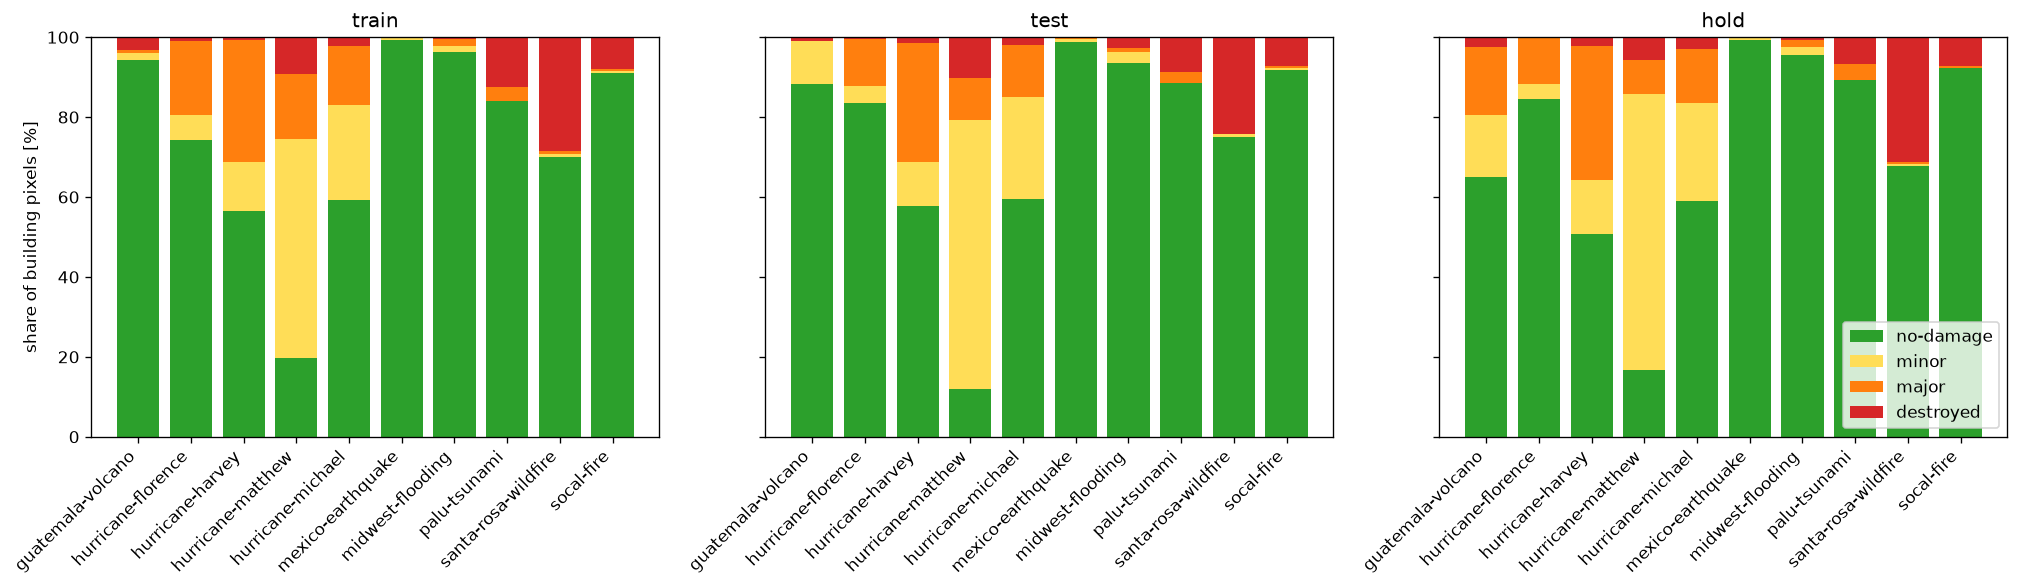

In [15]:
fig, ax = pl.subplots(1, 3, figsize=(17, 5), sharey=True)

for a, split in zip(ax, paths):
    disasters = sorted(damage_pct[split])
    bottom = np.zeros(len(disasters))

    for cls_name, color in zip(["no-damage", "minor", "major", "destroyed"],
                               ["#2ca02c", "#ffdd57", "#ff7f0e", "#d62728"]):
        values = [damage_pct[split][d][cls_name] for d in disasters]
        a.bar(disasters, values, bottom=bottom, label=cls_name, color=color)
        bottom += np.array(values)

    a.set_xticks(range(len(disasters)))
    a.set_xticklabels(disasters, rotation=45, ha="right")
    a.set_title(split)

ax[0].set_ylabel("share of building pixels [%]")
ax[2].legend(loc="lower right")
pl.tight_layout()
pl.show()

## 7. Building coverage per image

Checking the Building coverage per image for later training (empty images not very effective for building detection)

In [16]:

def building_presence(split):
    per_event = defaultdict(lambda: {"total": 0, "with_buildings": 0, "fractions": []})

    for pre_image in file_lists[split]:
        disaster = pre_image.split("_")[0]
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        fraction = (target > 0).mean()

        per_event[disaster]["total"] += 1
        per_event[disaster]["with_buildings"] += int(fraction > 0)
        if fraction >= config.MIN_BUILDING_FRACTION:
            per_event[disaster]["fractions"].append(fraction)

    return per_event


presence = {split: building_presence(split) for split in paths}

for split in paths:
    print(f"\n{split}:")
    for disaster, stats in sorted(presence[split].items()):
        pct_with = 100 * stats["with_buildings"] / stats["total"]
        mean_frac = 100 * np.mean(stats["fractions"]) if stats["fractions"] else 0.0
        print(f"  {disaster:22s}: {pct_with:5.1f}% of images have buildings, "
              f"mean building area {mean_frac:5.2f}%")


train:
  guatemala-volcano     :  94.4% of images have buildings, mean building area  2.45%
  hurricane-florence    :  95.9% of images have buildings, mean building area  2.27%
  hurricane-harvey      :  94.2% of images have buildings, mean building area 14.20%
  hurricane-matthew     :  93.7% of images have buildings, mean building area  2.83%
  hurricane-michael     :  97.4% of images have buildings, mean building area  8.55%
  mexico-earthquake     : 100.0% of images have buildings, mean building area 26.97%
  midwest-flooding      :  88.6% of images have buildings, mean building area  4.10%
  palu-tsunami          :  99.1% of images have buildings, mean building area 17.17%
  santa-rosa-wildfire   :  97.2% of images have buildings, mean building area  7.24%
  socal-fire            :  50.2% of images have buildings, mean building area  3.62%

test:
  guatemala-volcano     : 100.0% of images have buildings, mean building area  1.07%
  hurricane-florence    :  95.3% of images have bu

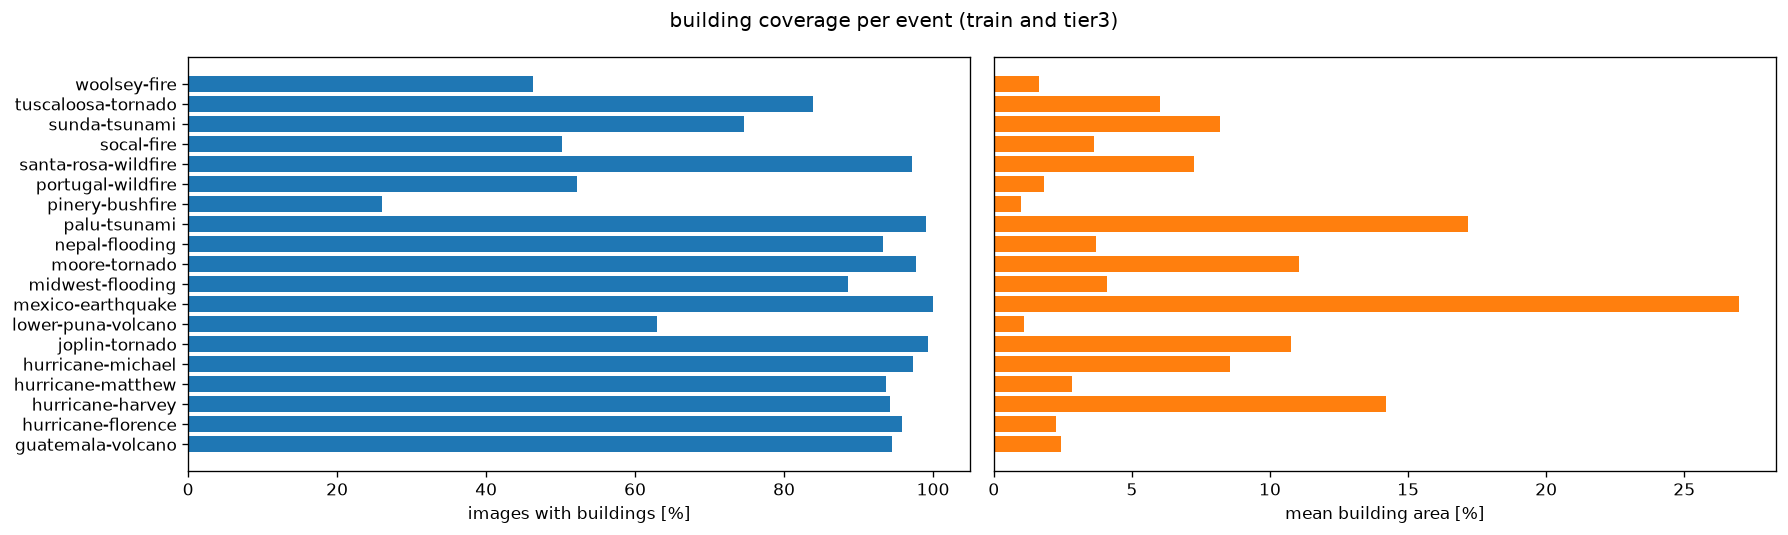

In [17]:
train_like = {}
for split in ("train", "tier3"):
    for disaster, stats in presence[split].items():
        train_like[disaster] = (
            100 * stats["with_buildings"] / stats["total"],
            100 * np.mean(stats["fractions"]) if stats["fractions"] else 0.0,
        )

events = sorted(train_like)
fig, ax = pl.subplots(1, 2, figsize=(15, 4.5))

ax[0].barh(events, [train_like[e][0] for e in events], color="C0")
ax[0].set_xlabel("images with buildings [%]")

ax[1].barh(events, [train_like[e][1] for e in events], color="C1")
ax[1].set_xlabel("mean building area [%]")
ax[1].set_yticks([])

fig.suptitle("building coverage per event (train and tier3)")
pl.tight_layout()
pl.show()

## 8. Example images per event

One pair with visible damage per event. The test events are the same as in
train, so only train and tier3 are shown.

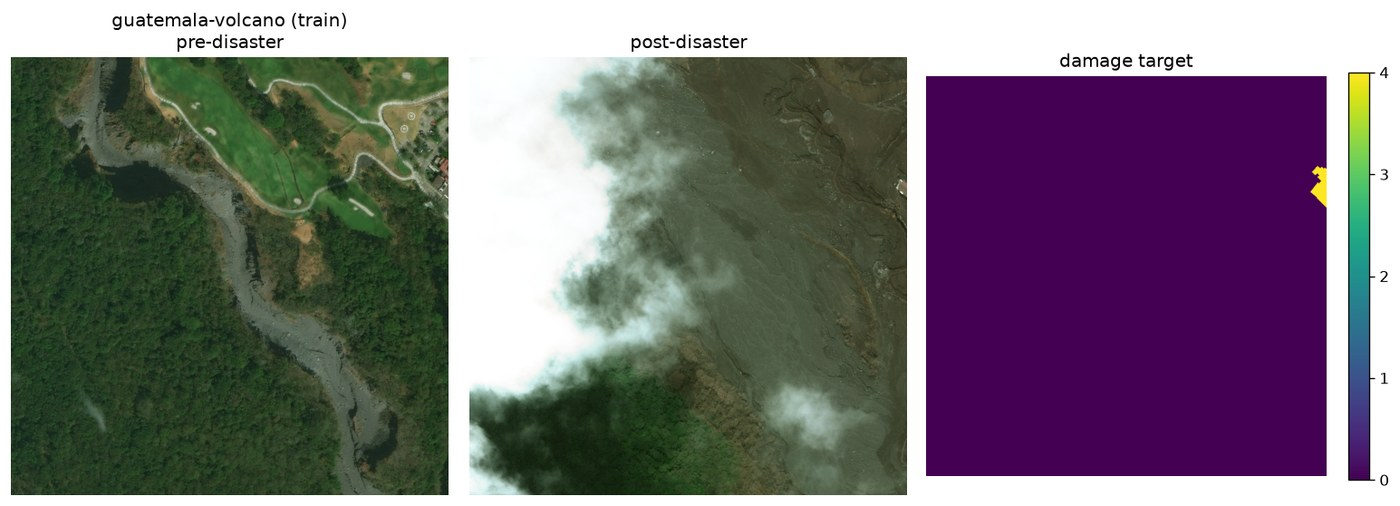

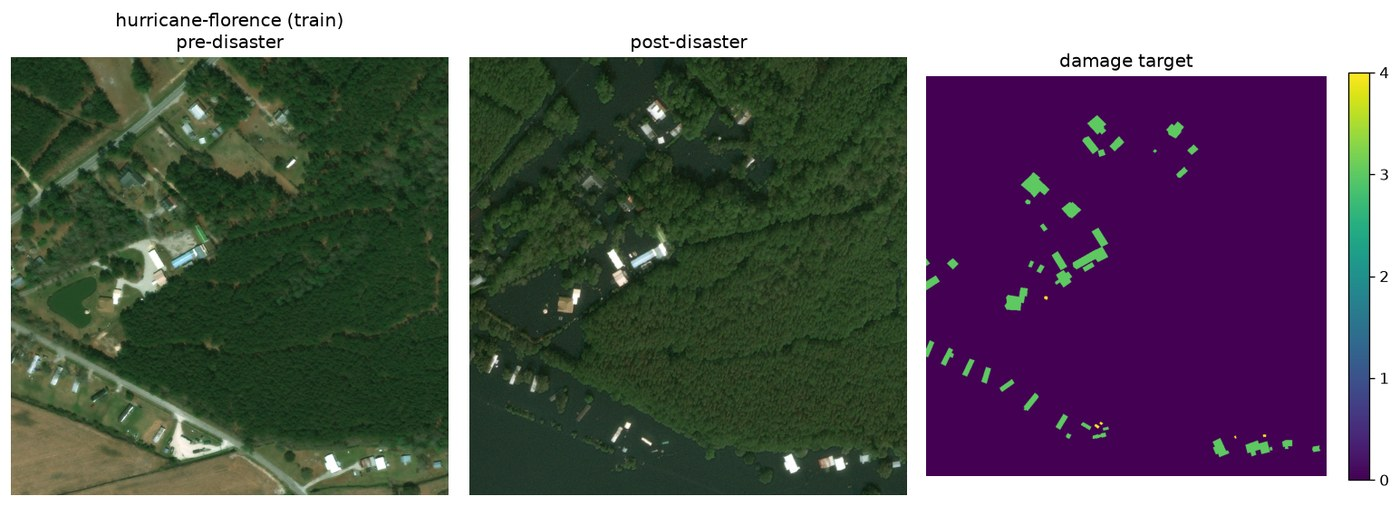

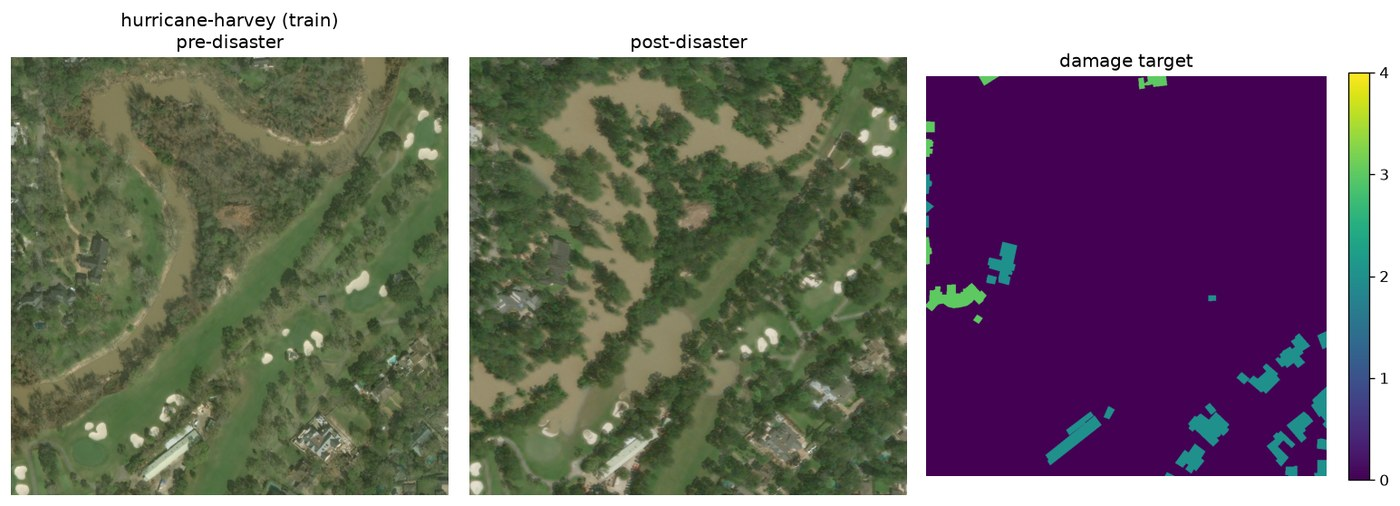

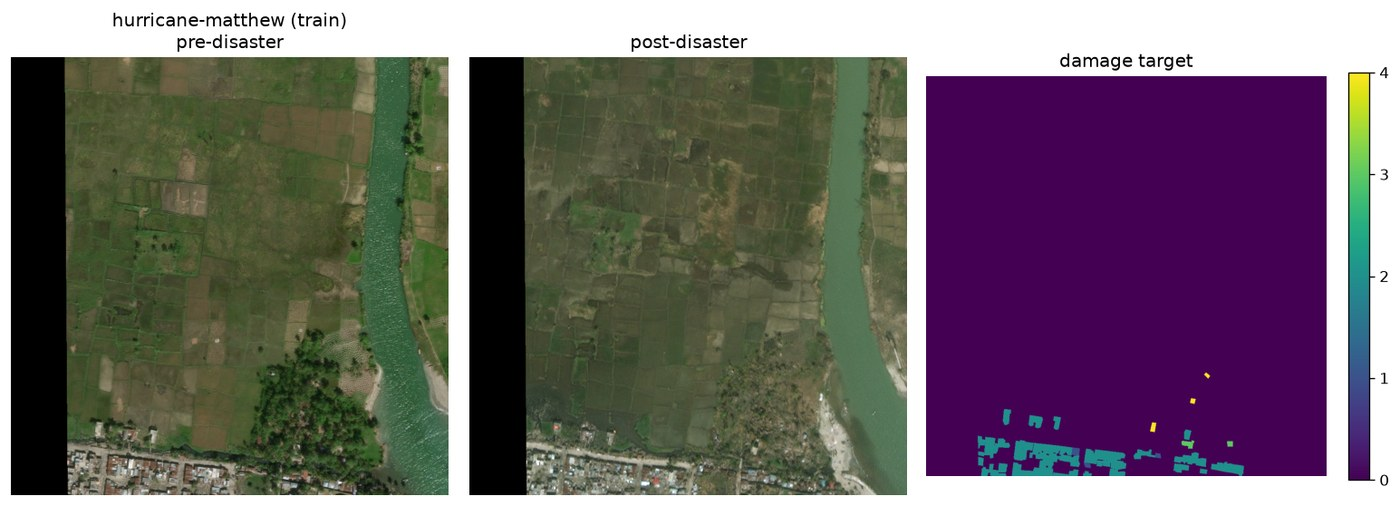

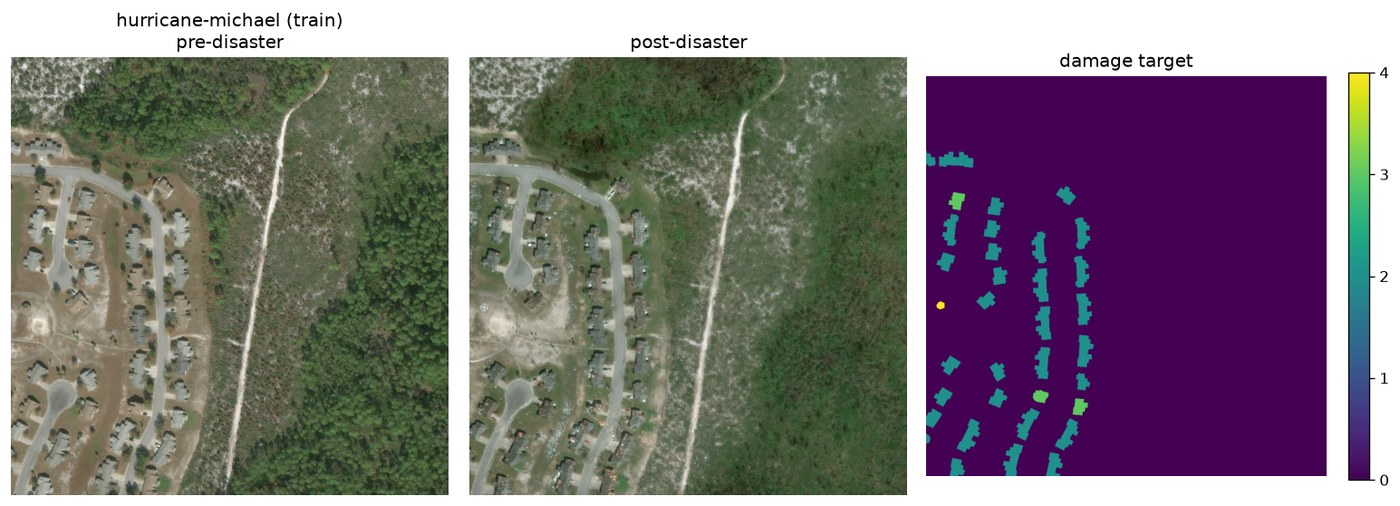

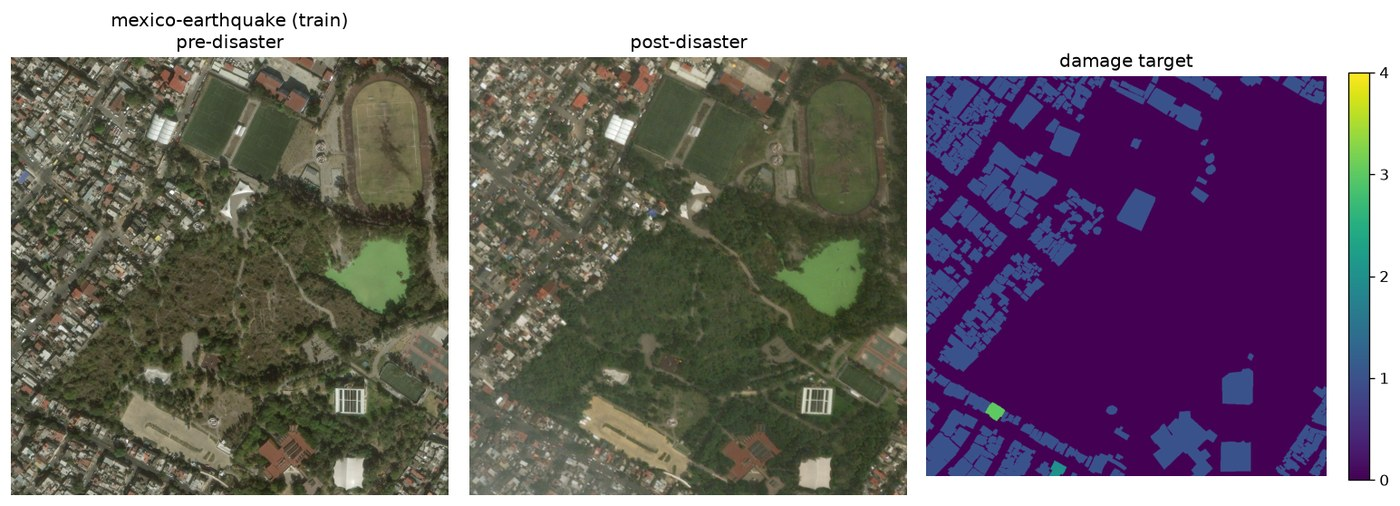

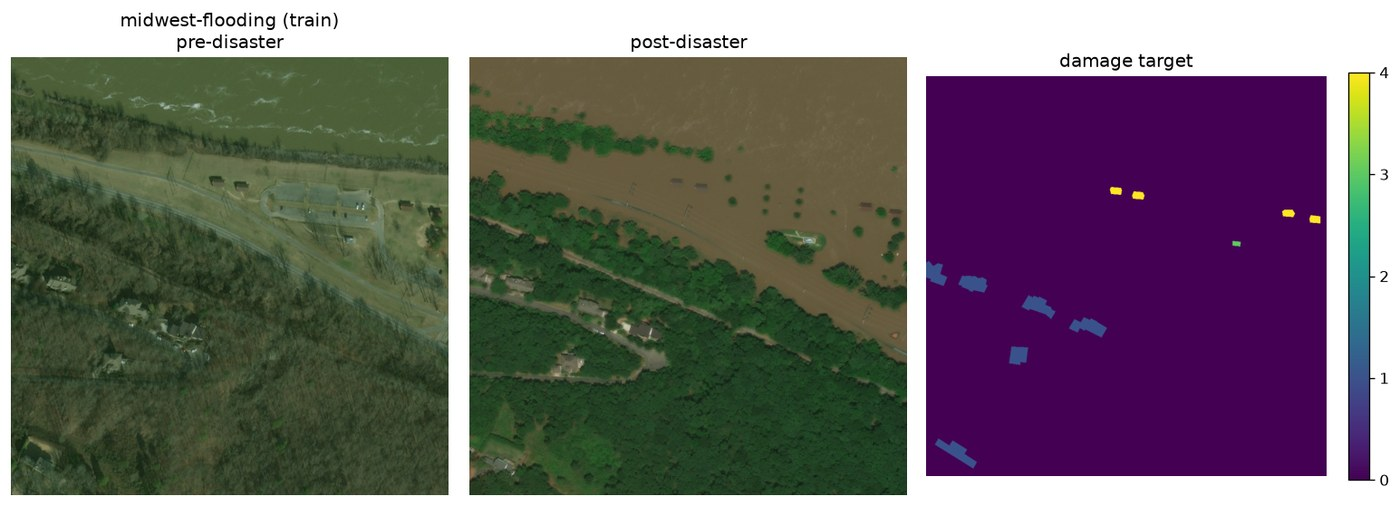

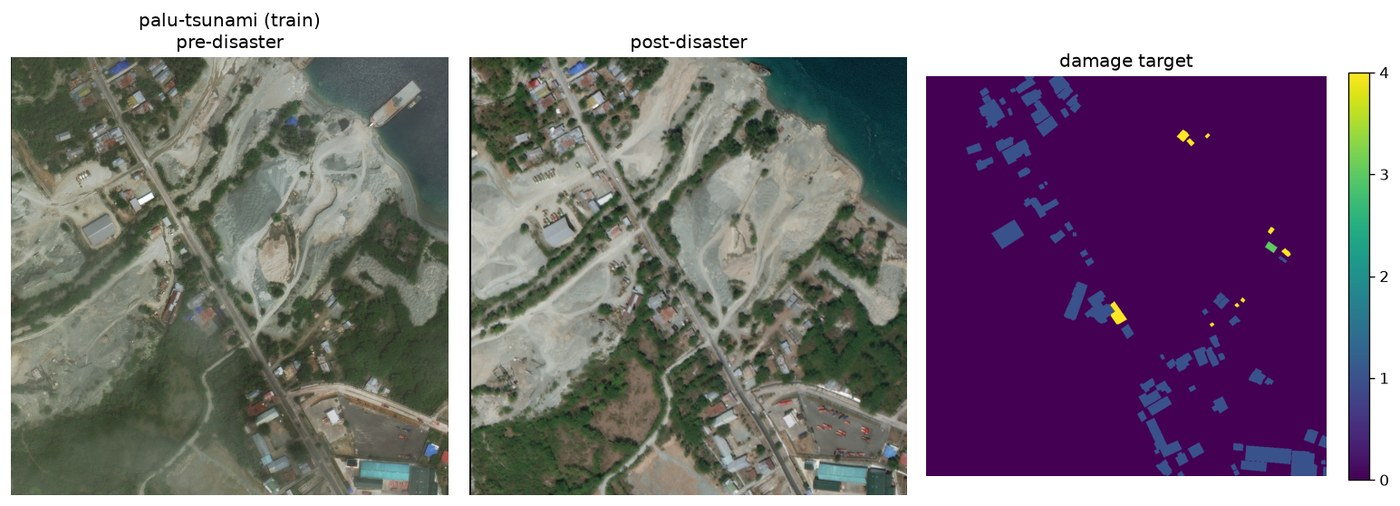

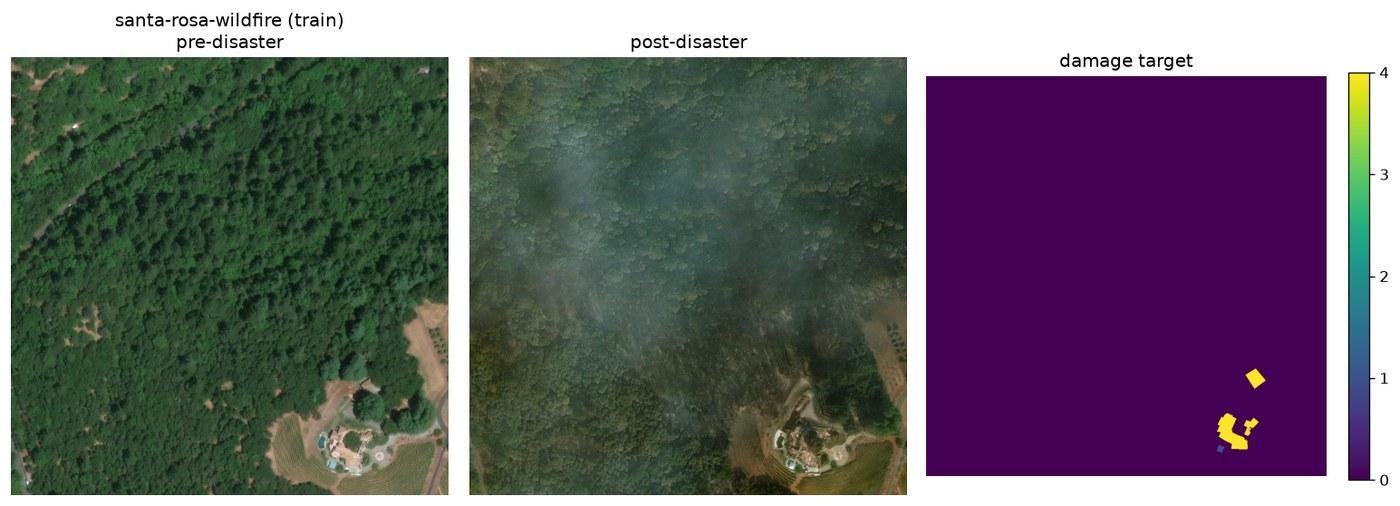

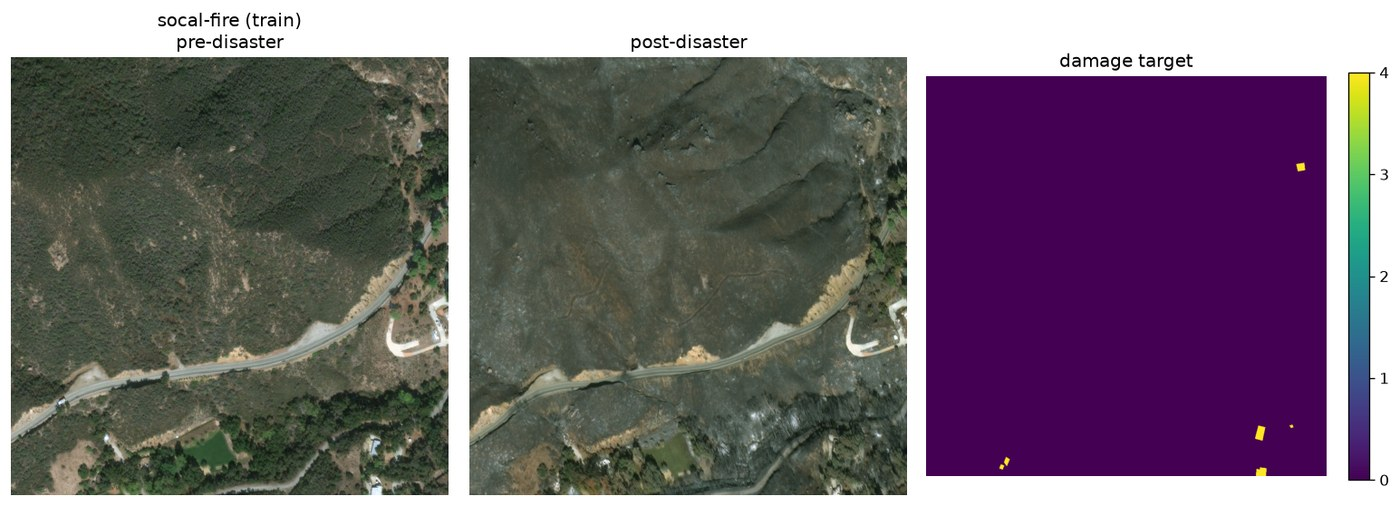

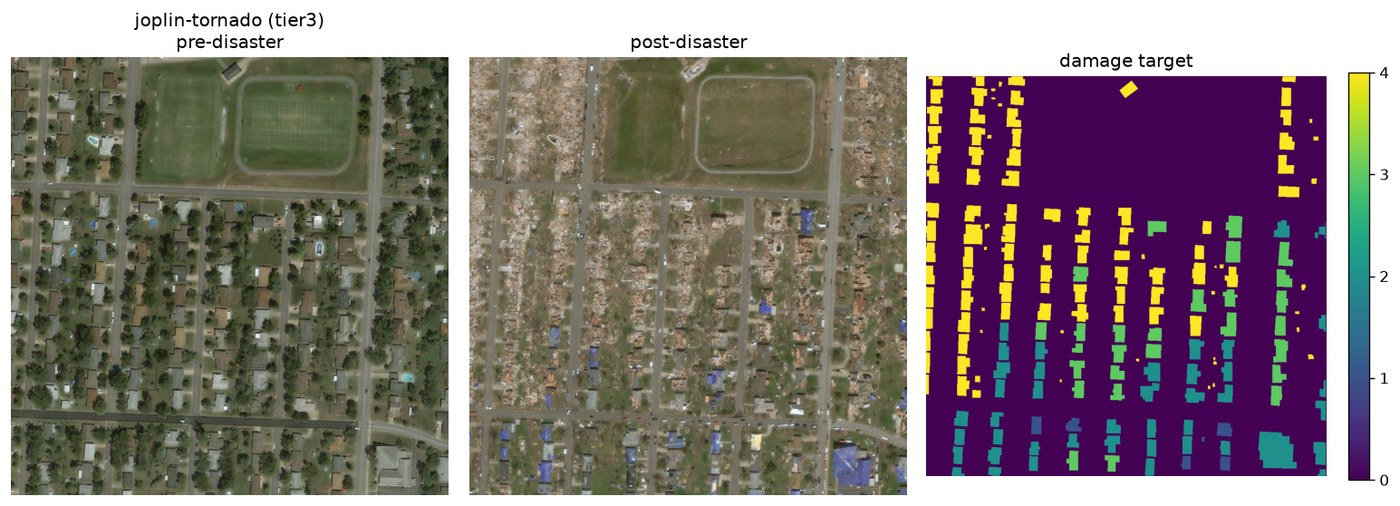

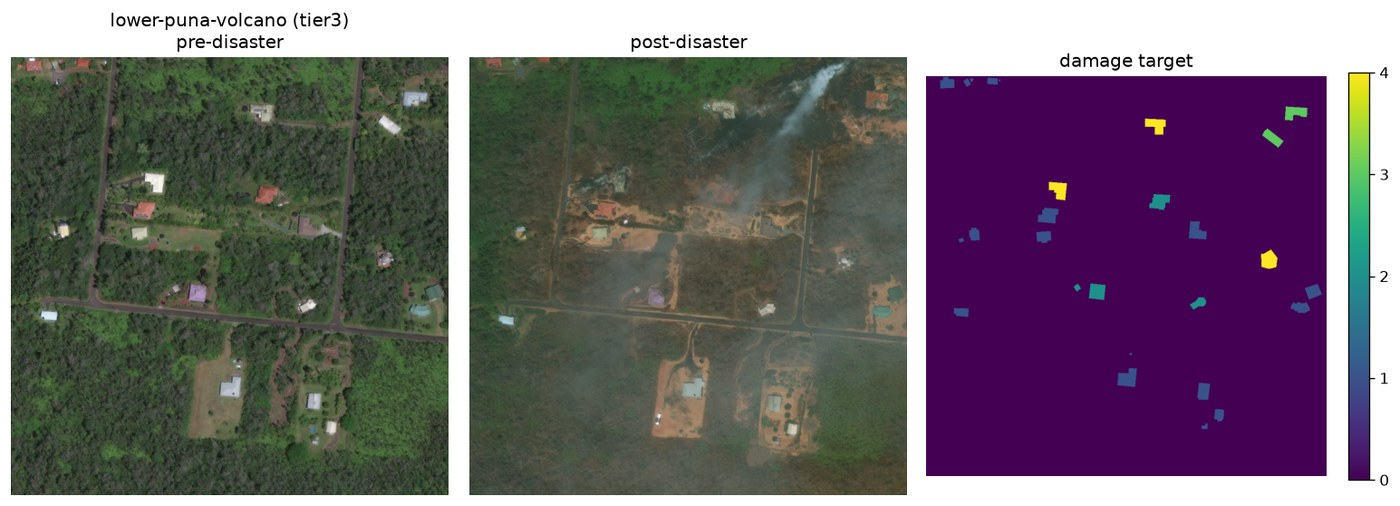

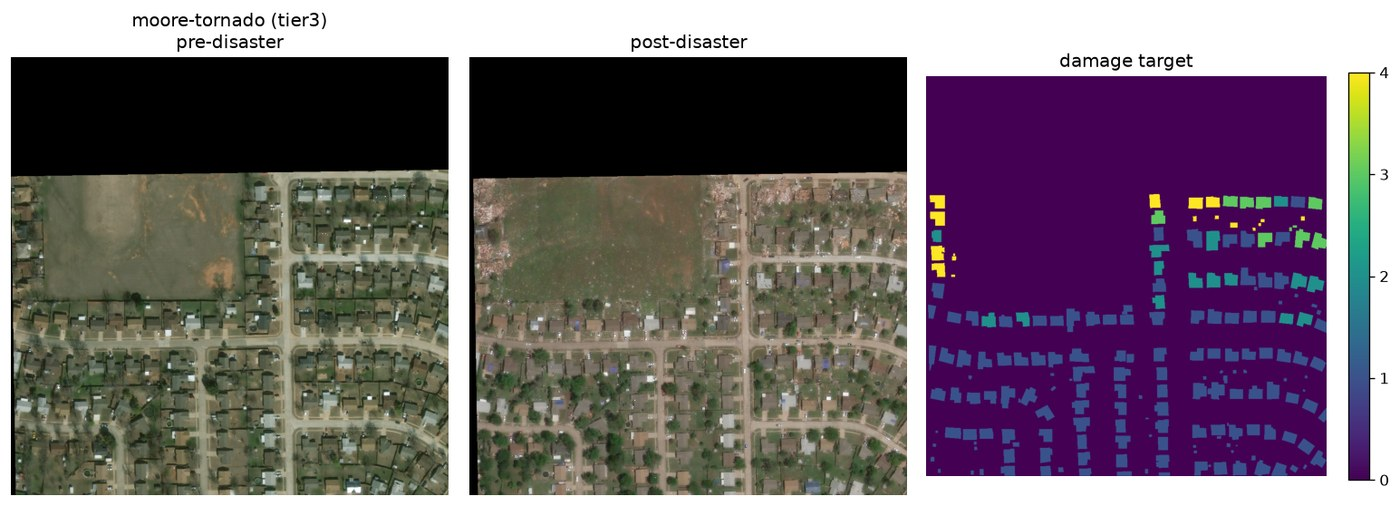

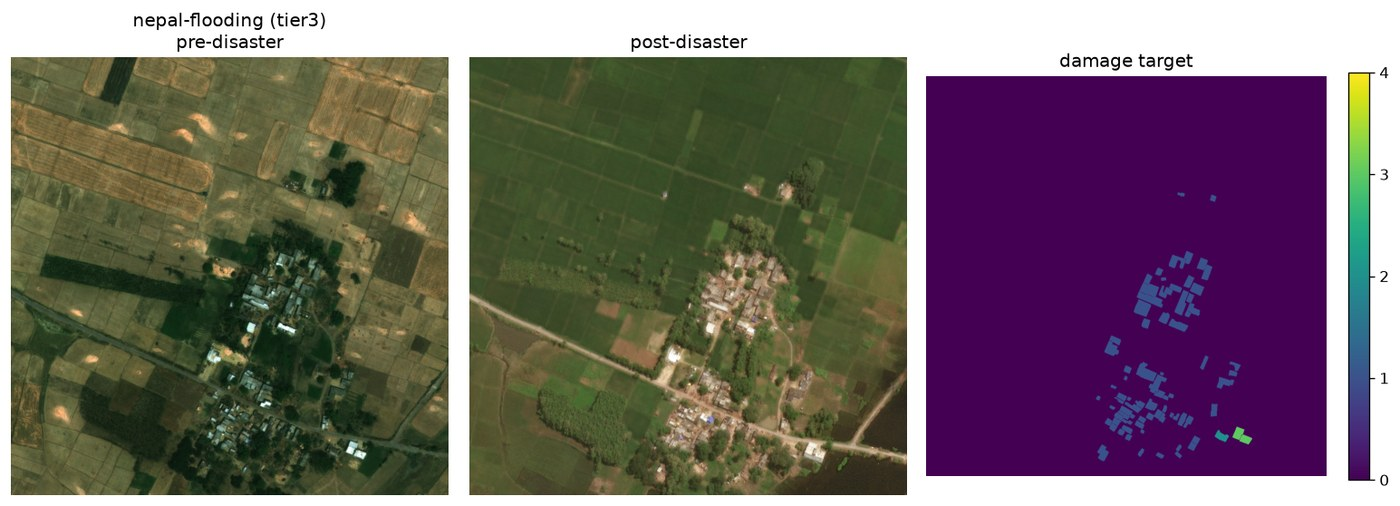

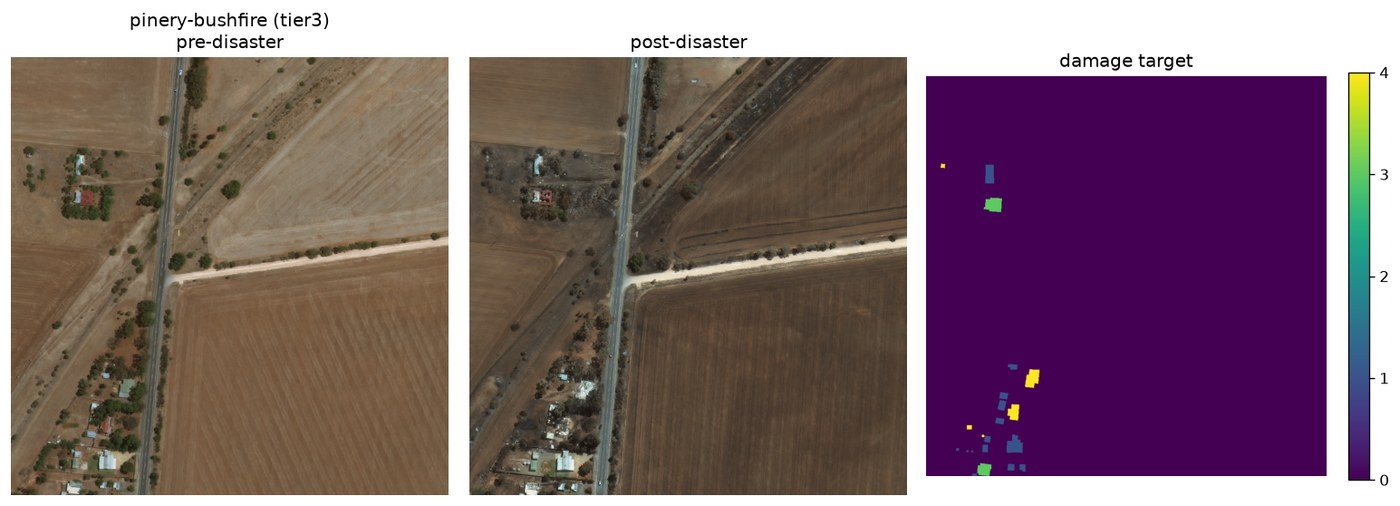

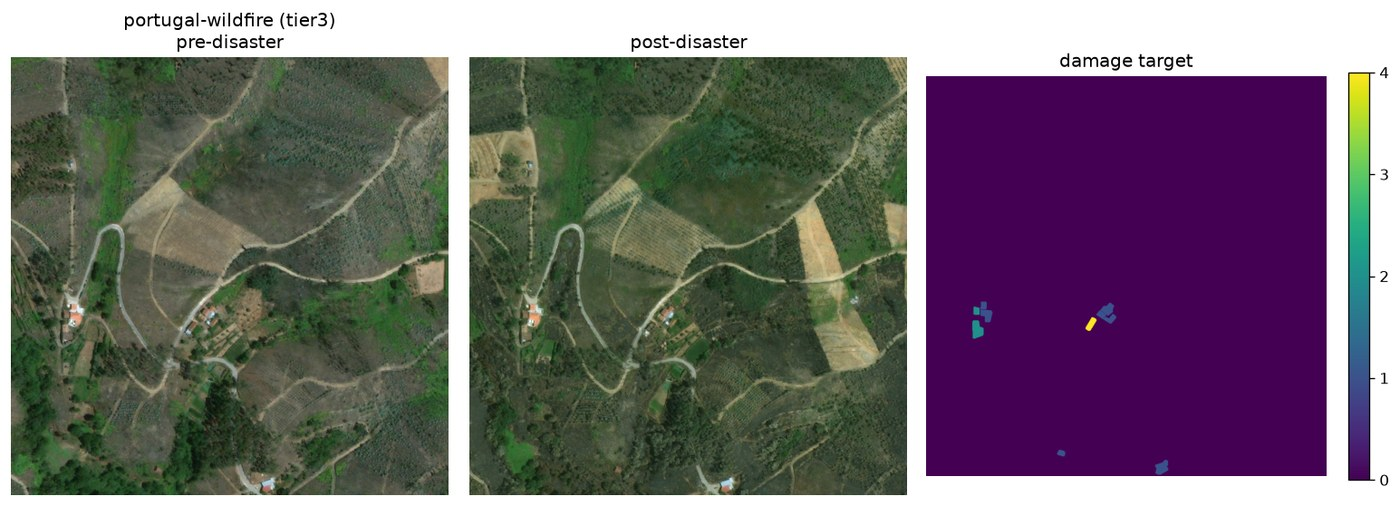

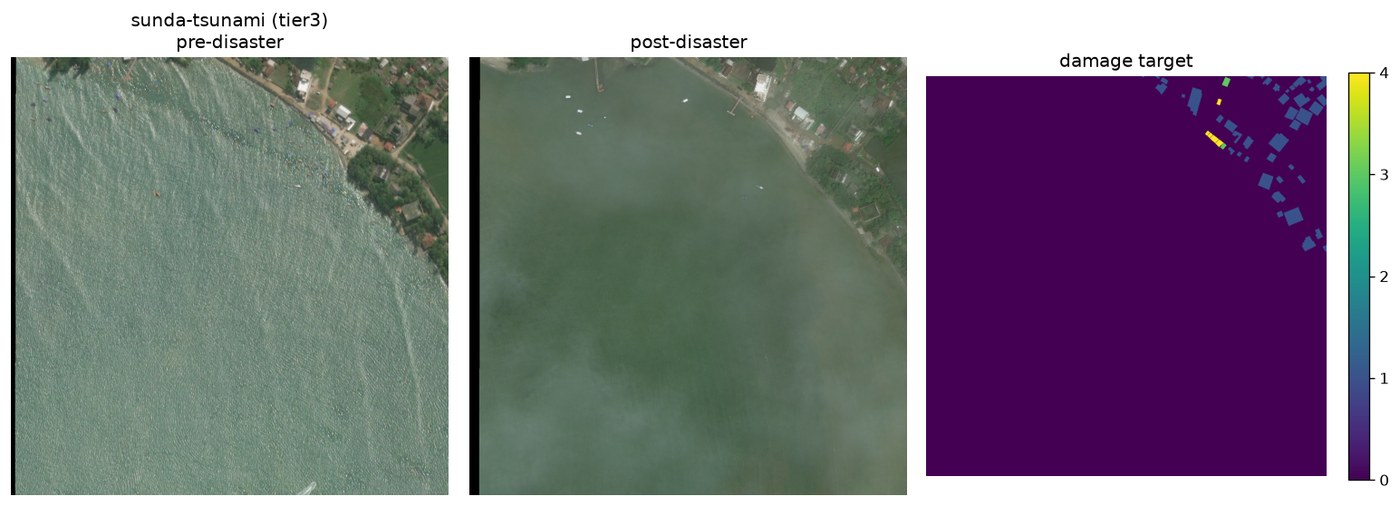

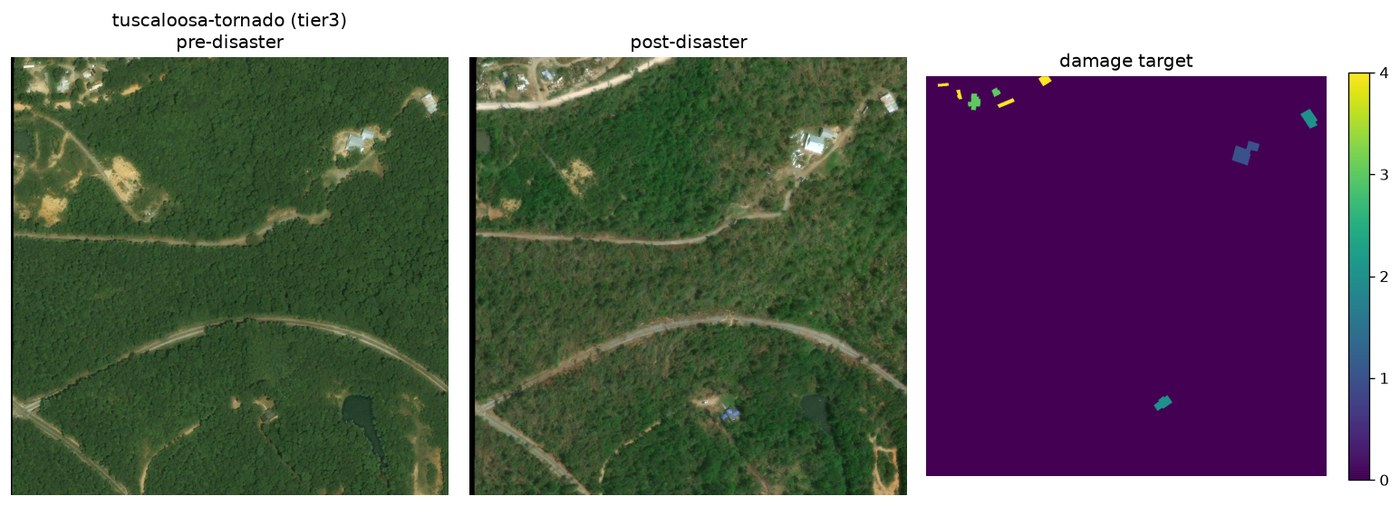

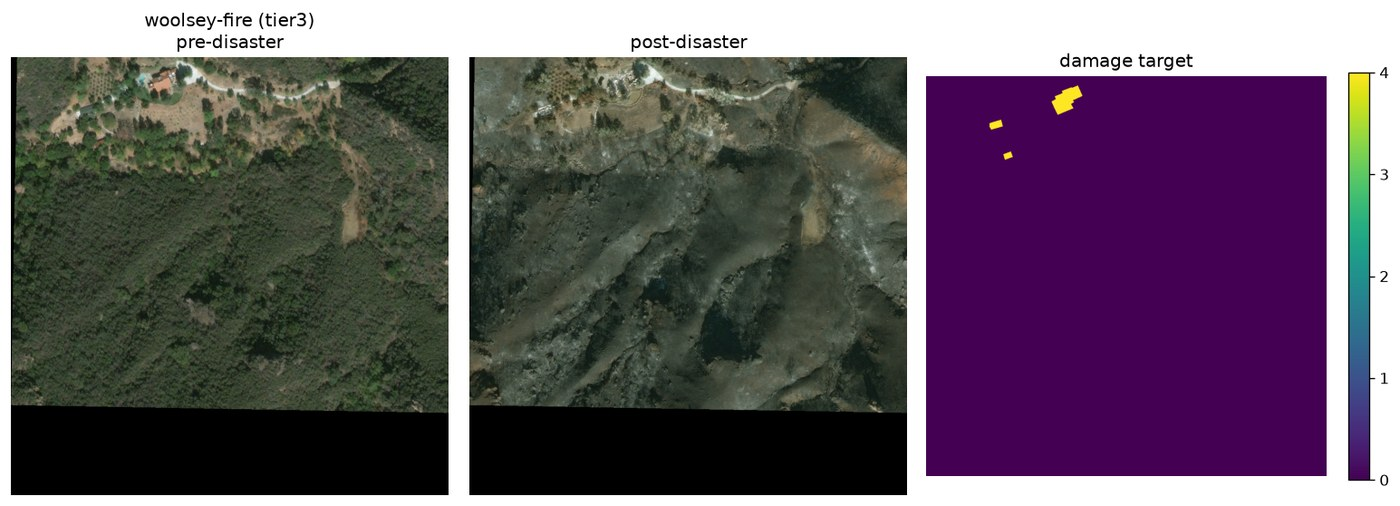

In [18]:
def show_event_example(split, disaster):
    candidates = [f for f in file_lists[split] if f.startswith(disaster)]
    if not candidates:
        return

    chosen = candidates[0]
    for c in candidates:
        stem = c.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_post_disaster_target.png")))
        if (target >= 3).any():
            chosen = c
            break

    stem = chosen.replace("_pre_disaster.png", "")
    pre_image = np.array(Image.open(os.path.join(paths[split]["images"], chosen)))
    post_image = np.array(Image.open(
        os.path.join(paths[split]["images"], f"{stem}_post_disaster.png")))
    post_target = np.array(Image.open(
        os.path.join(paths[split]["targets"], f"{stem}_post_disaster_target.png")))

    fig, ax = pl.subplots(1, 3, figsize=(13, 4.5))
    ax[0].imshow(pre_image)
    ax[0].set_title(f"{disaster} ({split})\npre-disaster")
    ax[1].imshow(post_image)
    ax[1].set_title("post-disaster")
    im = ax[2].imshow(post_target, cmap="viridis", vmin=0, vmax=4)
    ax[2].set_title("damage target")
    for a in ax:
        a.axis("off")

    pl.colorbar(im, ax=ax[2], ticks=[0, 1, 2, 3, 4], fraction=0.046)
    pl.tight_layout()
    pl.show()


for split in ("train", "tier3"):
    for disaster in sorted(event_counts[split]):
        show_event_example(split, disaster)

## 9. Image filter and cropping dataset

Images below `MIN_BUILDING_FRACTION` building area are dropped. The resulting
list is the training basis for the following notebooks.

In [19]:
all_building_files = []
for split in paths:
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        if (target > 0).mean() >= config.MIN_BUILDING_FRACTION:
            all_building_files.append((split, stem))

training_files = [(s, stem) for s, stem in all_building_files if s in ("train", "tier3")]
validation_files = [(s, stem) for s, stem in all_building_files if s == "test"]
holdout_files = [(s, stem) for s, stem in all_building_files if s == "hold"]

n_raw = sum(len(v) for v in file_lists.values())
print(f"{len(all_building_files)} of {n_raw} images pass the building filter")
print(f"  training   (train and tier3): {len(training_files)}")
print(f"  validation (test):            {len(validation_files)}")
print(f"  holdout    (hold):            {len(holdout_files)}")

6227 of 10884 images pass the building filter
  training   (train and tier3): 4836
  validation (test):            676
  holdout    (hold):            715


Instead of writing crops (256x256) to disk, the dataset cuts a new random tile on every
access. Tiles with more than `max_nodata_fraction` black pixels are discarded
without counting as an attempt; a tile is accepted once it holds at least
`min_tile_fraction` building pixels. After `max_attempts` the first valid tile
is returned as a negative example.

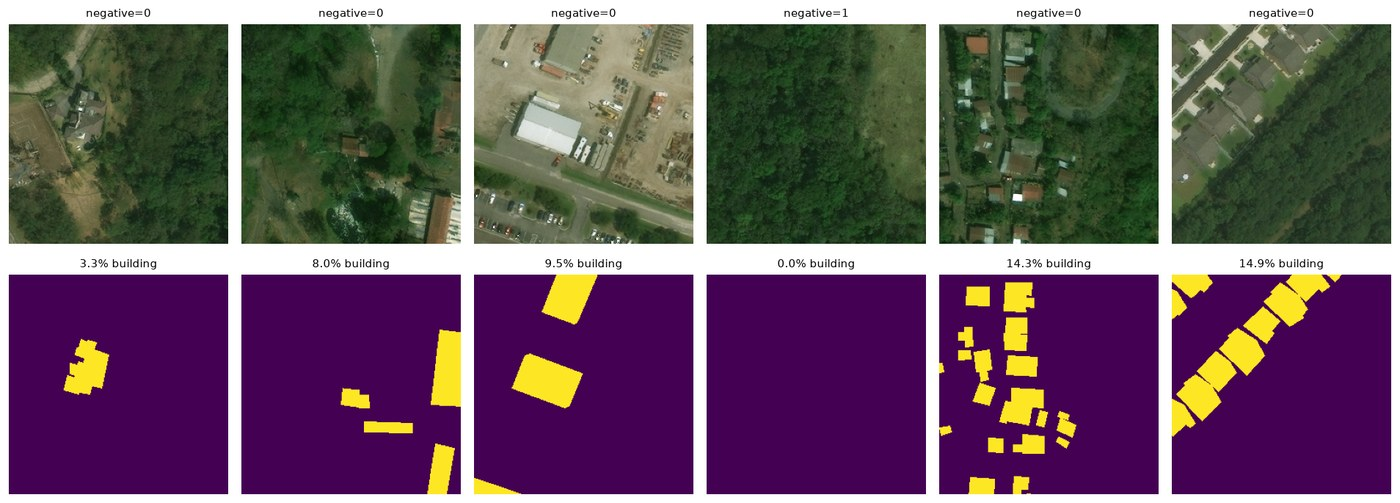

In [20]:
demo_dataset = crops.BuildingDataset(all_building_files[:30], paths)

fig, ax = pl.subplots(2, 6, figsize=(16, 6))
for a_img, a_tgt in zip(ax[0], ax[1]):
    tile_image, tile_target, is_negative = demo_dataset[np.random.randint(len(demo_dataset))]

    a_img.imshow(tile_image.permute(1, 2, 0))
    a_img.set_title(f"negative={is_negative}", fontsize=9)
    a_img.axis("off")

    a_tgt.imshow(tile_target, cmap="viridis", vmin=0, vmax=1)
    a_tgt.set_title(f"{100 * tile_target.float().mean():.1f}% building", fontsize=9)
    a_tgt.axis("off")

pl.tight_layout()
pl.show()